# Analyze the 1 m wheel-up run

This notebook reads `wheelsUp1meter.log` from this folder and plots the streamed robot measurements. The controller runs at 1 ms, while this log contains one row every 10 ms. The `desiredValue` column is the forward-speed reference in m/s; the reference-distance curve below is its numerical integral, not a separate logged target.

If the imports fail because packages are missing, install them in the notebook's Python environment with `%pip install pandas matplotlib`.

In [1]:
from pathlib import Path

try:
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
except ImportError as exc:
    raise ImportError(
        "Install the notebook dependencies with `%pip install pandas matplotlib` "
        "and rerun this cell."
    ) from exc

log_path = Path("wheelsUp1meter.log")
if not log_path.is_file():
    raise FileNotFoundError(f"Expected the log next to this notebook: {log_path.resolve()}")

columns = [
    "time_s", "state", "desired_speed_mps", "voltage_left_v", "voltage_right_v",
    "encoder_left", "encoder_right", "wheel_speed_left_radps", "wheel_speed_right_radps",
    "battery_v", "gyro_x_dps", "gyro_y_dps", "gyro_z_dps", "current_left_a",
    "current_right_a", "pose_x_m", "pose_y_m", "heading_rad", "distance_m",
    "forward_speed_mps", "turn_rate_radps",
]

data = pd.read_csv(
    log_path,
    comment="%",
    sep=r"\s+",
    header=None,
    names=columns,
)

if data.empty:
    raise ValueError(f"No numeric log rows found in {log_path}")
if data.isna().any().any():
    raise ValueError("Some log rows do not contain all 21 expected numeric columns")

data.head()

,time_s,state,desired_speed_mps,voltage_left_v,voltage_right_v,encoder_left,encoder_right,wheel_speed_left_radps,wheel_speed_right_radps,battery_v,...,gyro_y_dps,gyro_z_dps,current_left_a,current_right_a,pose_x_m,pose_y_m,heading_rad,distance_m,forward_speed_mps,turn_rate_radps
0,0.009,10,0.0,0.00,0.00,0,0,0.00,0.00,5.06,...,0.14,0.06,0.19,-0.18,0.0,0.0,0.0,0.0,0.00,0.00
1,0.019,10,0.0,0.00,0.00,0,0,0.00,0.00,5.06,...,-0.31,0.18,0.19,-0.17,0.0,0.0,0.0,0.0,0.00,0.00
2,0.029,11,0.2,7.33,7.33,1,2,0.00,0.00,3.67,...,-0.62,-0.25,2.88,-2.22,0.0,0.0,0.0,0.0,0.00,0.00
3,0.039,11,0.2,-3.68,-3.04,8,8,91.58,86.25,4.72,...,-0.25,-0.13,0.82,-1.53,0.0,0.0,0.0,0.0,0.29,-0.12
4,0.049,11,0.2,1.11,1.61,11,11,51.69,47.53,5.04,...,1.12,-0.46,0.17,-0.15,0.0,0.0,0.0,0.0,0.16,-0.09


In [2]:
time = data["time_s"].to_numpy()
dt = np.diff(time)
duration_s = float(time[-1] - time[0]) if len(time) > 1 else 0.0
median_interval_s = float(np.median(dt)) if len(dt) else float("nan")

print(f"Rows: {len(data)}")
print(f"Time range: {time[0]:.4f} to {time[-1]:.4f} s ({duration_s:.3f} s recorded)")
print(f"Median log interval: {median_interval_s:.4f} s")
print(f"Observed states: {sorted(data['state'].unique().tolist())}")
display(data[[
    "desired_speed_mps", "forward_speed_mps", "distance_m", "voltage_left_v",
    "voltage_right_v", "battery_v", "current_left_a", "current_right_a",
]].describe().T.round(3))

Rows: 673
Time range: 0.0090 to 6.7287 s (6.720 s recorded)
Median log interval: 0.0100 s
Observed states: [10, 11, 12]


,count,mean,std,min,25%,50%,75%,max
desired_speed_mps,673.0,0.190,0.043,0.00,0.20,0.20,0.20,0.20
forward_speed_mps,673.0,0.149,0.033,-0.07,0.15,0.16,0.16,0.29
distance_m,673.0,0.521,0.302,0.00,0.26,0.52,0.78,1.00
voltage_left_v,673.0,1.559,0.662,-6.03,1.51,1.64,1.80,7.33
voltage_right_v,673.0,1.452,0.680,-5.99,1.22,1.56,1.81,7.33
battery_v,673.0,5.010,0.069,3.67,5.00,5.01,5.03,5.07
current_left_a,673.0,0.293,0.129,0.15,0.24,0.28,0.32,2.88
current_right_a,673.0,-0.205,0.119,-2.22,-0.21,-0.19,-0.18,-0.13


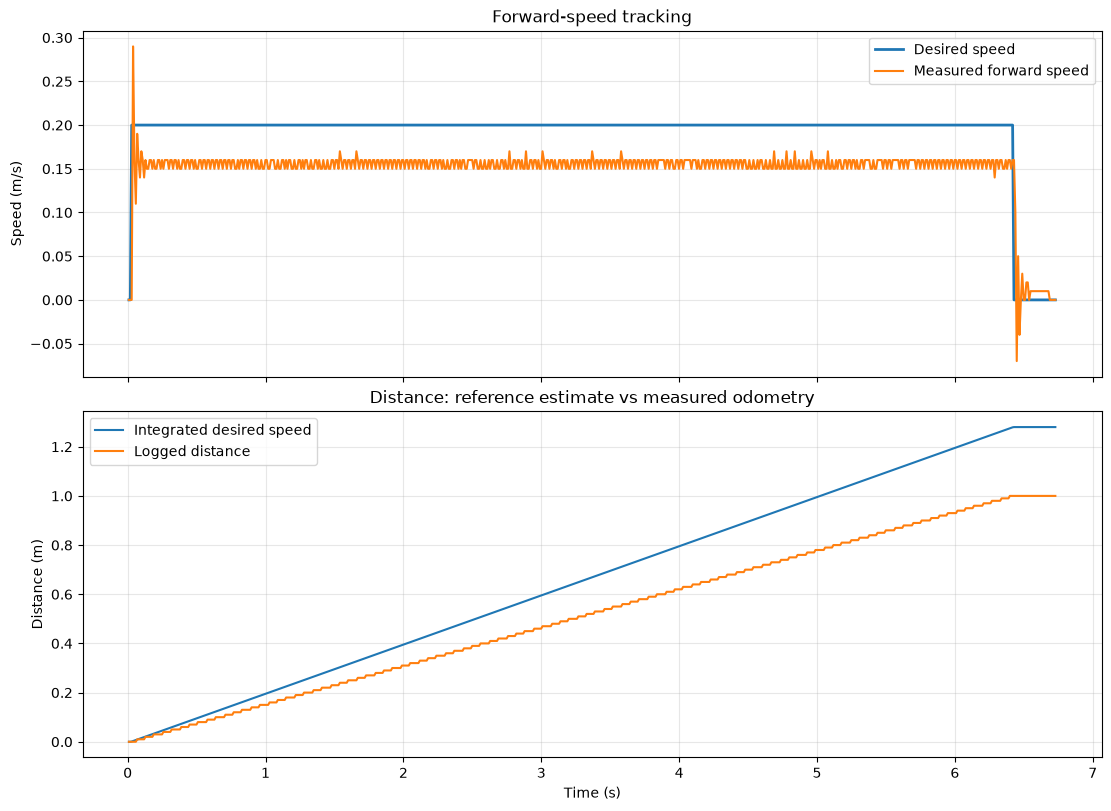

Final logged distance: 1.000 m
Final integrated reference distance: 1.280 m


In [3]:
# Integrate the speed reference using the measured, possibly nonuniform log intervals.
reference_speed = data["desired_speed_mps"].to_numpy()
reference_distance = np.zeros(len(data))
if len(data) > 1:
    reference_distance[1:] = np.cumsum(
        0.5 * (reference_speed[:-1] + reference_speed[1:]) * dt
    )

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True, constrained_layout=True)
axes[0].plot(time, reference_speed, label="Desired speed", linewidth=2)
axes[0].plot(time, data["forward_speed_mps"], label="Measured forward speed")
axes[0].set_ylabel("Speed (m/s)")
axes[0].set_title("Forward-speed tracking")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(time, reference_distance, label="Integrated desired speed")
axes[1].plot(time, data["distance_m"], label="Logged distance")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Distance (m)")
axes[1].set_title("Distance: reference estimate vs measured odometry")
axes[1].grid(True, alpha=0.3)
axes[1].legend()
plt.show()

print(f"Final logged distance: {data['distance_m'].iloc[-1]:.3f} m")
print(f"Final integrated reference distance: {reference_distance[-1]:.3f} m")

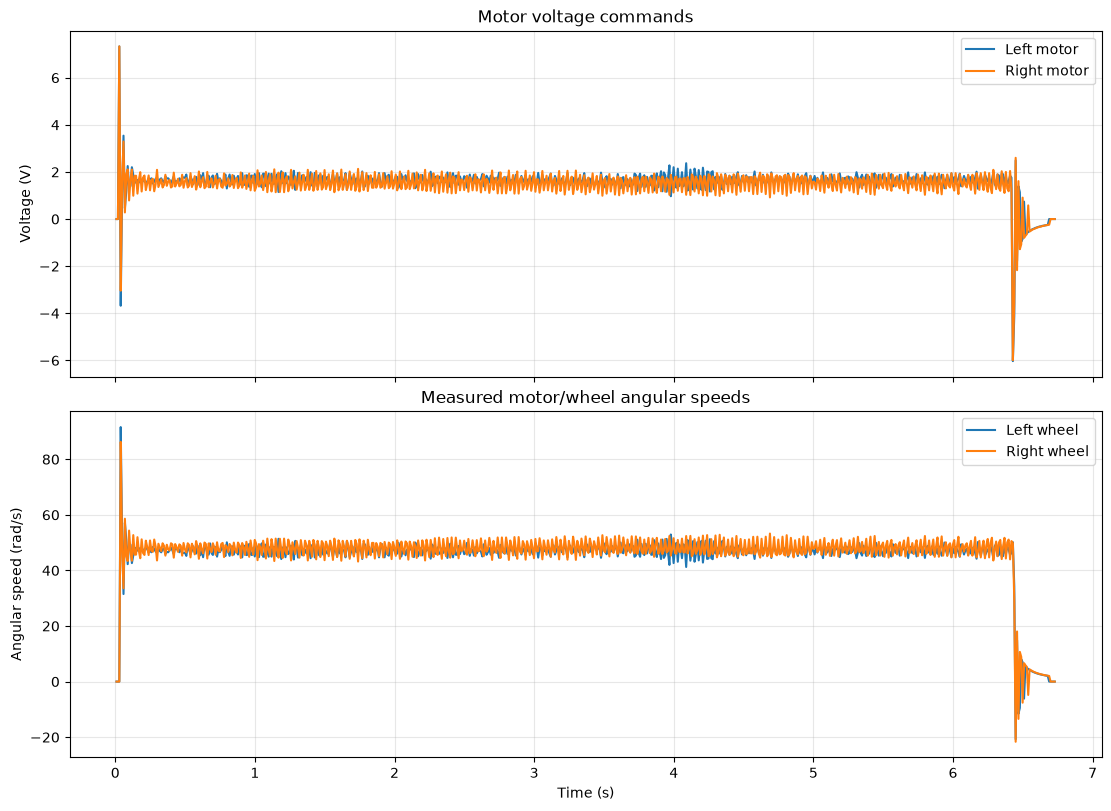

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True, constrained_layout=True)
axes[0].plot(time, data["voltage_left_v"], label="Left motor")
axes[0].plot(time, data["voltage_right_v"], label="Right motor")
axes[0].set_ylabel("Voltage (V)")
axes[0].set_title("Motor voltage commands")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(time, data["wheel_speed_left_radps"], label="Left wheel")
axes[1].plot(time, data["wheel_speed_right_radps"], label="Right wheel")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Angular speed (rad/s)")
axes[1].set_title("Measured motor/wheel angular speeds")
axes[1].grid(True, alpha=0.3)
axes[1].legend()
plt.show()

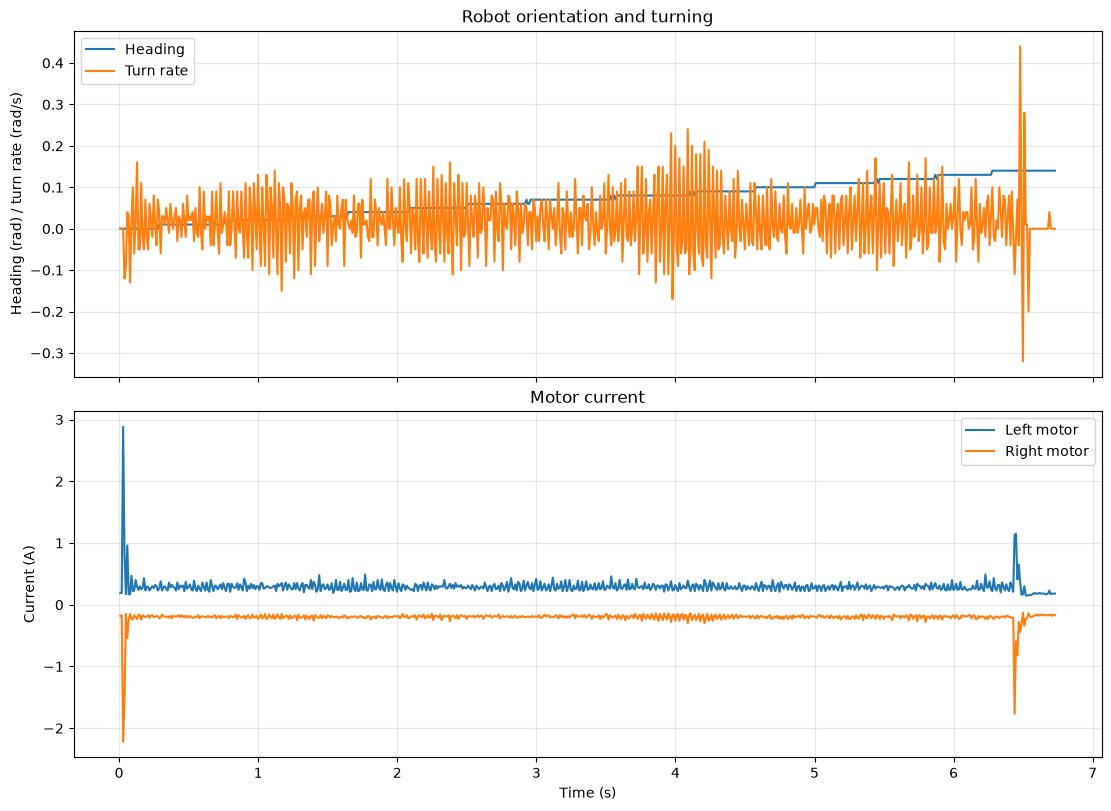

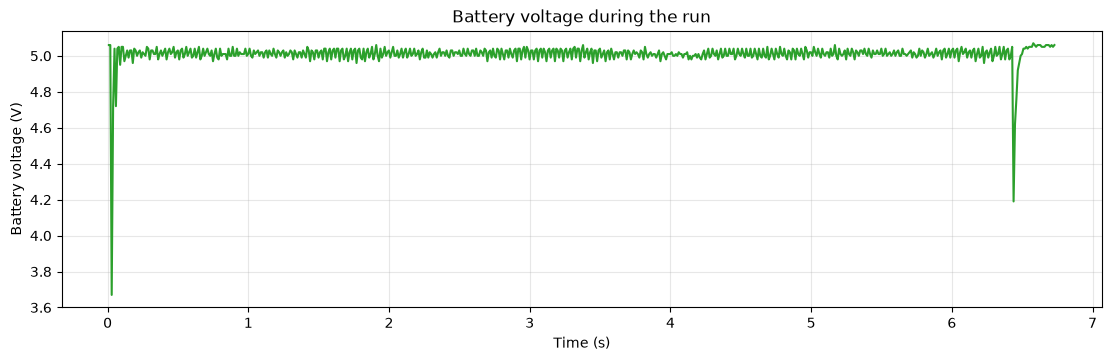

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True, constrained_layout=True)
axes[0].plot(time, data["heading_rad"], label="Heading")
axes[0].plot(time, data["turn_rate_radps"], label="Turn rate")
axes[0].set_ylabel("Heading (rad) / turn rate (rad/s)")
axes[0].set_title("Robot orientation and turning")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(time, data["current_left_a"], label="Left motor")
axes[1].plot(time, data["current_right_a"], label="Right motor")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Current (A)")
axes[1].set_title("Motor current")
axes[1].grid(True, alpha=0.3)
axes[1].legend()
plt.show()

fig, ax = plt.subplots(figsize=(11, 3.5), constrained_layout=True)
ax.plot(time, data["battery_v"], color="tab:green")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Battery voltage (V)")
ax.set_title("Battery voltage during the run")
ax.grid(True, alpha=0.3)
plt.show()